<a href="https://colab.research.google.com/github/814725243109/energy_consumption_analysis/blob/main/EDA%20assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime

# Set style for visualizations
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Generate synthetic hourly data for 30 days
np.random.seed(42)
date_range = pd.date_range(start="2024-01-01", periods=24 * 30, freq="h")

# Simulate consumption patterns
base_load = np.random.normal(loc=2.0, scale=0.3, size=len(date_range))
peak_hours = (date_range.hour >= 17) & (date_range.hour <= 21)
peak_load = peak_hours * np.random.normal(loc=3.5, scale=0.8, size=len(date_range))

consumption_kwh = np.maximum(0.5, base_load + peak_load)

# Create DataFrame
df = pd.DataFrame({
    'Timestamp': date_range,
    'Consumption_kWh': consumption_kwh,
    'Appliance': np.random.choice(['HVAC', 'Refrigeration', 'Lighting', 'EV Charging'], size=len(date_range)),
    'Customer_Segment': np.random.choice(['Residential', 'Commercial', 'Industrial'], size=len(date_range), p=[0.5, 0.3, 0.2]),
    'Temperature_C': np.random.uniform(15, 35, size=len(date_range))
})

# Feature engineering
df['Hour'] = df['Timestamp'].dt.hour
df['DayOfWeek'] = df['Timestamp'].dt.day_name()
df['Month'] = df['Timestamp'].dt.month

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (720, 8)


,Timestamp,Consumption_kWh,Appliance,Customer_Segment,Temperature_C,Hour,DayOfWeek,Month
0,2024-01-01 00:00:00,2.149014,Lighting,Commercial,20.306523,0,Monday,1
1,2024-01-01 01:00:00,1.958521,Lighting,Commercial,27.031078,1,Monday,1
2,2024-01-01 02:00:00,2.194307,EV Charging,Residential,20.931198,2,Monday,1
3,2024-01-01 03:00:00,2.456909,EV Charging,Residential,29.288483,3,Monday,1
4,2024-01-01 04:00:00,1.929754,Lighting,Residential,30.180106,4,Monday,1


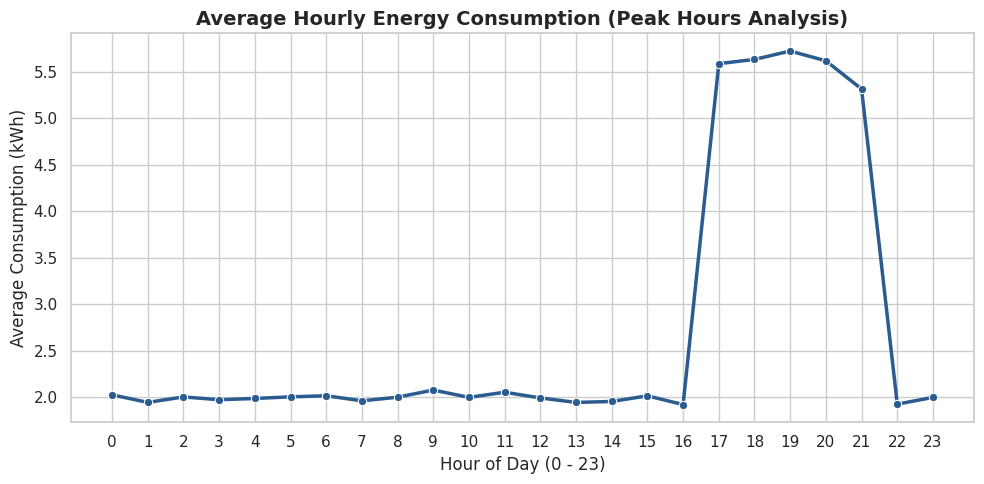

In [14]:
plt.figure(figsize=(10, 5))
hourly_avg = df.groupby('Hour')['Consumption_kWh'].mean()
sns.lineplot(x=hourly_avg.index, y=hourly_avg.values, marker='o', color='#2b5c8f', linewidth=2.5)

plt.title('Average Hourly Energy Consumption (Peak Hours Analysis)', fontsize=14, fontweight='bold')
plt.xlabel('Hour of Day (0 - 23)', fontsize=12)
plt.ylabel('Average Consumption (kWh)', fontsize=12)
plt.xticks(range(0, 24))
plt.tight_layout()
plt.savefig('hourly_energy_trend.png', dpi=300)
plt.show()

/tmp/ipykernel_3884/3056886058.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Customer_Segment', y='Consumption_kWh', data=segment_totals, palette='Blues_r')


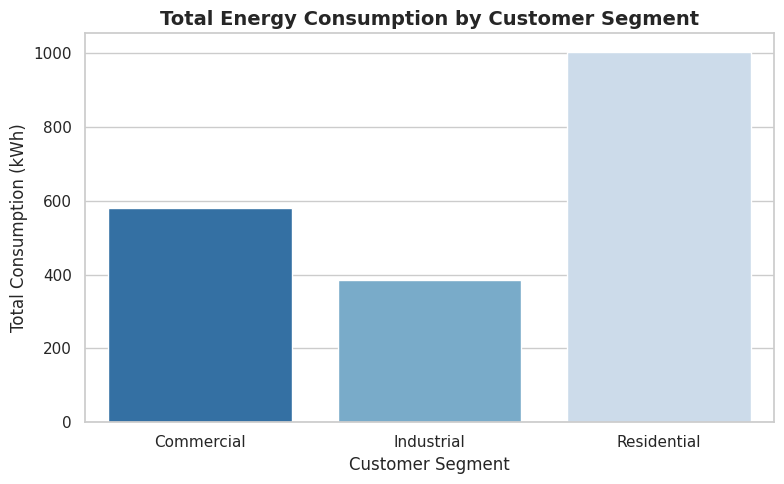

In [15]:
plt.figure(figsize=(8, 5))
segment_totals = df.groupby('Customer_Segment')['Consumption_kWh'].sum().reset_index()

sns.barplot(x='Customer_Segment', y='Consumption_kWh', data=segment_totals, palette='Blues_r')
plt.title('Total Energy Consumption by Customer Segment', fontsize=14, fontweight='bold')
plt.xlabel('Customer Segment', fontsize=12)
plt.ylabel('Total Consumption (kWh)', fontsize=12)
plt.tight_layout()
plt.savefig('segment_consumption.png', dpi=300)
plt.show()

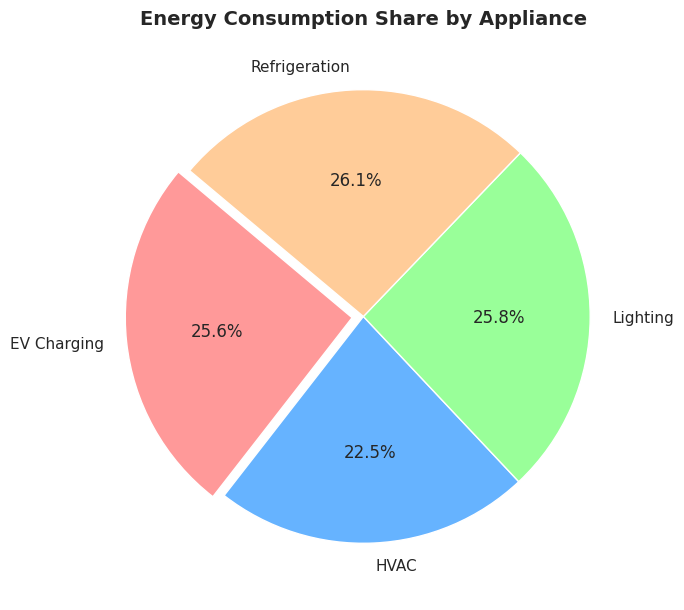

In [16]:
appliance_totals = df.groupby('Appliance')['Consumption_kWh'].sum()

plt.figure(figsize=(7, 7))
colors = ['#ff9999','#66b3ff','#99ff99','#ffcc99']
plt.pie(appliance_totals, labels=appliance_totals.index, autopct='%1.1f%%', startangle=140, colors=colors, explode=(0.05, 0, 0, 0))
plt.title('Energy Consumption Share by Appliance', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('appliance_share.png', dpi=300)
plt.show()

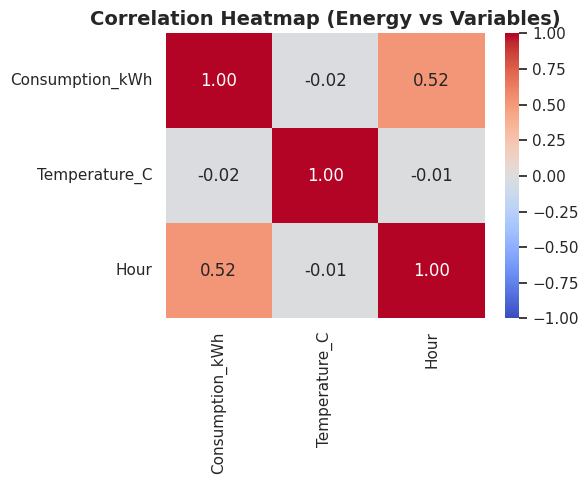

In [17]:
plt.figure(figsize=(6, 5))
numeric_df = df[['Consumption_kWh', 'Temperature_C', 'Hour']].corr()

sns.heatmap(numeric_df, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f")
plt.title('Correlation Heatmap (Energy vs Variables)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=300)
plt.show()